rumz
# Notebook for processing layers in ice
### May 25
#### V. 2.1
- Updated with better bubble detection and inpainting
- Uses Median and Mean, not just Sum


This notebook processes hyperspectral images of ice and extracts information in regards to climate proxies.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
import warnings
import sys
import os
import datetime
import matplotlib.pyplot as plt

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from Sums import sums_process_module as processSums
from icespec import savePNG
from icespec import ageConversion

### Users should fill in variables with desired core info
Use HSI_July2024 Spreadsheet for ID and section names

Debug variable prints more information during processing

In [2]:
DataID = "HSIUM-104" #insert DataID from excel file inside quotation marks

## This should be its own function ##
NumID = int(DataID.split('-')[-1])
if NumID <= 228:
    datasetPath = '/data/icecores/HSI_2024.csv'
elif 229 <= NumID < 335:
    datasetPath = '/data/icecores/HSI_2023_1.csv'
elif 335 <= NumID < 363:
    datasetPath = '/data/icecores/HSI_June2025.csv'
elif 363 <= NumID < 586:
    datasetPath = '/data/icecores/HSI_Sept2025.csv'
elif 586 <= NumID < 751:
    datasetPath = '/data/icecores/HSI_Denali2025.csv'
elif 751 <= NumID < 873:
    datasetPath = '/data/icecores/HSI_Jan2024.csv'
else:
    raise ValueError(f"NumID {NumID} is outside supported ranges (<=228, 229–334, 335–362, 363–585, 586–750, 751–872). \n Please check DataID and try again.")
    

outputDir = '/data/icecores/Output' #png output path
SCRIPT_ID = "LayersNB"

Debug = True
Save = True

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)

outputPath = processice.make_dir(save_path, SCRIPT_ID, metadata)
print("Output Path: ", outputPath)

data_nparr, w_ref, d_ref, wvls, fwhm = processice.getEnviData(dataPath)

Core:  ALHIC 2302
Section:  29 Sec 33
Lighting: Top light - 100%, Bottom Light - 0%
Exposure:  16
Top Depth:  26.07
Bottom Depth:  27.03
Length =  0.9600000000000009
Dimensions:  1390, 6770, 150,850
Data Path:  July2024/ALHIC2302-29_0003_HSI_UM_Jul24
Output Path:  /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-29/2026-03-24_151133
<class 'numpy.ndarray'>


In [4]:
segment_boundaries, px_per_cm = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=px_dims[1])
print("pixels per cm: ", px_per_cm)

core bottom depth: 27.03 - core top depth: 26.07 = core length: 0.9600000000000009
core length cm: 96.00000000000009
end px: 6770 - start px: 1200 = total px height: 5570
ice height px: 5570 / core length cm: 96.00000000000009 = px per cm: 58.02083333333328
standard px height: 325 / standard length: 5.08 = px per cm: 63.976377952755904
pixels per cm:  63.976377952755904


In [5]:
#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
dataSize = [2000, 3000, 200, 400]
stdSize = [530, 820, 200, 900] #standard sizing

The new dimensions will be: 650x5380
Trimmed shapes: (5380, 650, 224), W_ref: (175, 650, 224), D_ref: (100, 650, 224)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Reflectance calculated. Dimensions: (5380, 650, 224)


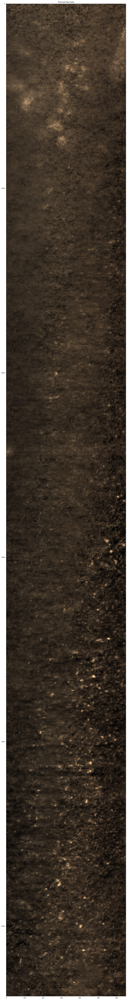

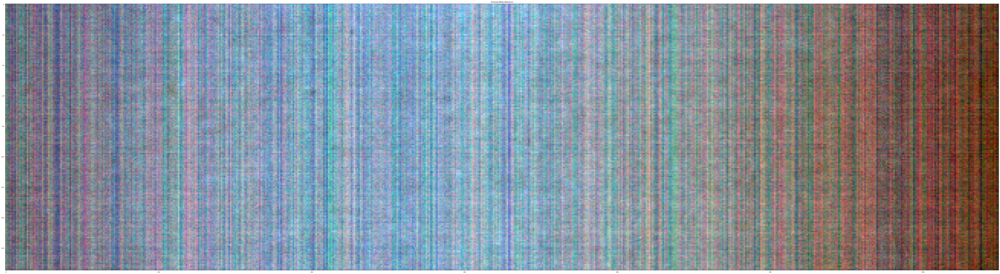

In [6]:
trimmedData = processice.trim(data_nparr, w_ref, d_ref, px_dims, stdSize, Debug=Debug) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)

--- SNR Proxy Stats ---
Min SNR: 79.5412
Max SNR: 20935.5914
Mean SNR: 9082.8190
-----------------------
[   79.54116828    81.25716618   110.06473051   146.00080089
   215.18288083   306.49529297   387.60307438   501.59887421
   645.32349534   691.26425442   895.37855213  1085.16470071
  1192.91291167  1392.21491317  1519.31636529  1669.21153204
  1789.4931198   1758.51246143  1970.06706066  1933.5138331
  1852.93169626  2193.51473221  2323.08797326  2243.98547896
  2778.25326818  3064.44688897  2938.25440978  3464.51650391
  4057.01229848  4189.61837683  4579.84154339  5116.79182081
  5233.34720163  5475.58743696  5938.21657541  5599.21127264
  5510.43794373  5956.627175    5932.3632184   5344.90949845
  5778.05831348  6663.37232855  6739.47936293  6211.34797579
  6945.60541114  8115.22157012  8405.51710929  8068.14685285
  9117.63788291 10191.0599416  10412.13135098 10544.85021385
 11281.69700165 12485.53915632 12639.3006136  12370.44160822
 12647.2991703  12981.81669924 12343.81214

<Figure size 640x480 with 0 Axes>

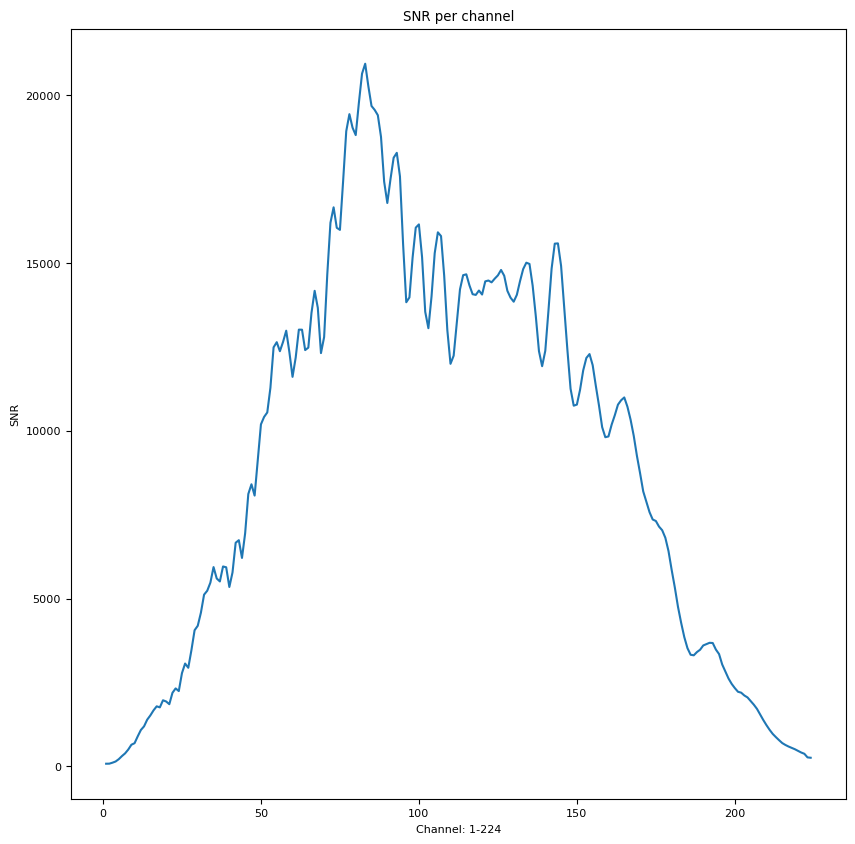

Good Bands:  []
Bad Bands:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 2

In [7]:
filtered_img, wvls, fwhm = processice.remove_bands(correctedData, trimmedData[1], wvls, fwhm, Debug=True, outputPath=outputPath, save=True)
filename = f"{DataID}filtered.png"
rgb_slice = filtered_img[:, :, [34, 21, 13]].astype(np.float32)
rgb_norm = (rgb_slice - rgb_slice.min()) / (rgb_slice.max() - rgb_slice.min())
plt.imsave(f"{outputPath}/{filename}", rgb_norm, dpi=600)
readme_path = outputPath / "README.md"
with readme_path.open("a") as f:
    f.write(f"\n###  Output File: {filename}\n- {DataID}: Image of Filtered Data post Ref Correction\n")

In [8]:
from sklearn.decomposition import PCA
import numpy as np

# filtered_img shape: (rows, cols, bands)
rows, cols, bands = filtered_img.shape
depth = filtered_img.shape[0]
print(filtered_img.shape[0])

X = filtered_img.reshape(-1, bands)  # (rows*cols, bands)
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X)  # (rows*cols, 5)
pcs_img = X_pca.reshape(rows, cols, 5)

# px_per_m = px_per_cm * 100



depths_cm = 2607 + (np.arange(depth) / px_per_cm)
print(depths_cm.shape)

5380
(5380,)


In [9]:
# Average across columns (x-direction)
pcs_depth = np.mean(pcs_img, axis=1)  

In [10]:
import pandas as pd
import numpy as np

k = pcs_depth.shape[1]

# Build column names
pc_cols = [f"PC{i+1}" for i in range(k)]

# Combine depth + PCs
df_pca = pd.DataFrame(
    np.column_stack((depths_cm, pcs_depth)),
    columns=["Depth_cm"] + pc_cols
)

# Save to CSV
df_pca.to_csv(f"{outputPath}/pca_by_depth.csv", index=False)

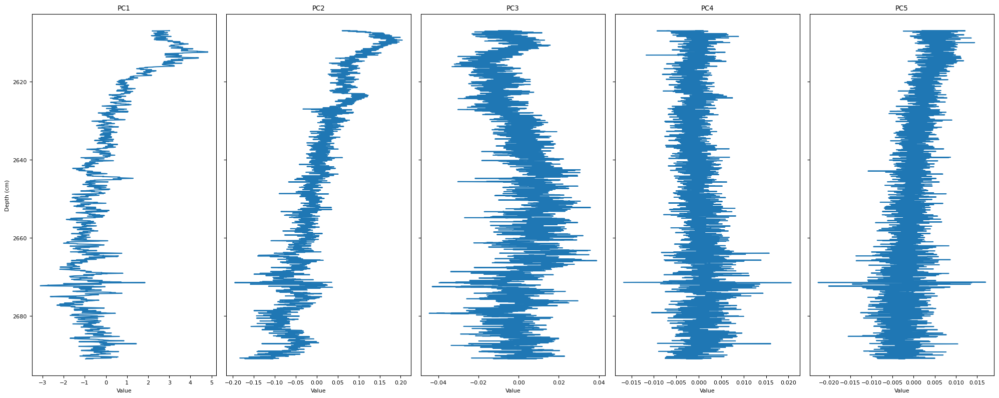

In [11]:
import matplotlib.pyplot as plt

k = pcs_depth.shape[1]

fig, axes = plt.subplots(1, k, figsize=(4*k, 8), sharey=True)

if k == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.plot(pcs_depth[:, i], depths_cm)
    ax.set_title(f"PC{i+1}")
    ax.set_xlabel("Value")
    if i == 0:
        ax.set_ylabel("Depth (cm)")
    ax.invert_yaxis()

plt.tight_layout()
plt.show()